# S1 · Government collapse: what the 8 clean episodes show

When a government falls, what happens to trust in parliament? This notebook looks at the **8 past episodes where the result can be read most safely** and puts France next to them.

**What this is:** a side-by-side description of 8 cases. It fits no model, estimates no effect, and makes no forecast.

**What "clean" means:** no parliamentary election and no other reviewed government crisis happened between the event and the survey that measures "after". Other shocks can still overlap, and the flags below say which ones.

**Part 1 (sections 1 to 8) looks at 8 carefully dated episodes. Part 2 (sections 9 to 13) widens the set to every government in the EU since 2005 that fell or lost its majority: 31 cases with a usable trust window, 19 of them clean.**

France (Barnier, December 2024) is **held out**: it is the case we want to apply the results to, so it is shown for comparison but never used to build the picture. The reasoning behind each case is in [`docs/s1_review_cases.md`](../docs/s1_review_cases.md); every column is defined in [`s1_variable_dictionary.csv`](../data/processed/s1_variable_dictionary.csv).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from trust_windows import ISO3_TO_EB, load_waves

pd.set_option('display.float_format', '{:.1f}'.format)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 60)
BLUE, RED, GREY, LIGHT = '#245f91', '#c45d3f', '#8a98a6', '#d9e2ea'

COUNTRY = {'BGR': 'Bulgaria', 'CZE': 'Czechia', 'EST': 'Estonia', 'FRA': 'France', 'MLT': 'Malta',
           'NLD': 'Netherlands', 'ROU': 'Romania', 'SVK': 'Slovakia', 'SWE': 'Sweden'}
HOW = {'successful_no_confidence_vote': 'lost a no-confidence vote', 'budget_vote_defeat': 'lost a budget vote',
       'resignation_after_budget_talks_failed': 'resigned after budget talks failed',
       'resignation_after_party_withdrawal': 'resigned after a party withdrew'}
GOV = {'MWC': 'minimal-winning coalition', 'MPMi': 'multi-party minority', 'SPMi': 'single-party minority',
       'SPMa': 'single-party majority', 'OC': 'oversized coalition'}

d = pd.read_csv(ROOT / 'data/processed/s1_episode_dataset.csv')
d['flags'] = d['flags'].fillna('')
d['episode'] = [f"{COUNTRY[r.iso3]} {r.episode_id.split('_')[1]}" for r in d.itertuples()]
d['short'] = [f"{r.iso3} {r.episode_id.split('_')[1][2:]}" for r in d.itertuples()]
d['event_date'] = pd.to_datetime(d.event_date)

CHANGE = 'parl_change_beyond_comparison_pp'
clean = d[d.sample_group == 'clean'].sort_values('event_date').reset_index(drop=True)
broad = d[d.sample_group == 'broad_only']
france = d[d.sample_group == 'held_out'].iloc[0]
print(f"{len(d)} reviewed S1 episodes, in these groups:")
d.sample_group.value_counts().rename('episodes').to_frame()

14 reviewed S1 episodes, in these groups:


,episodes
sample_group,
clean,8
broad_only,3
no_post_wave,2
held_out,1


## 1. Which episodes are in

| Group | Meaning |
| --- | --- |
| **clean** | The 8 episodes this notebook describes. |
| **broad_only** | A complete trust window, but an election falls before the "after" survey (Bulgaria 2022, Malta 2012, Netherlands 2012). Shown in grey for context only. |
| **no_post_wave** | No survey starts 3 to 9 months after the event yet (Romania 2018 and 2019). |
| **held_out** | France 2024. Compared with the 8, never part of them. |

**Four of the eight are Romanian.** Their governments and voters are not independent of each other, so the sample is smaller than it looks.

## 2. The eight episodes

How each government fell, what kind of government it was, and how trust in parliament moved. *Before* is the average of the two Eurobarometer surveys before the event; *after* is the first survey starting 3 to 9 months later. *vs. other countries* subtracts the change in EU countries where no reviewed event happened in the same period, so a Europe-wide movement is not counted.

In [2]:
t = pd.DataFrame({
    'Episode': clean.episode,
    'Date': clean.event_date.dt.strftime('%d %b %Y'),
    'How it fell': clean.event_type.map(HOW),
    'Government': clean.government_type.map(GOV),
    'Seat share': clean.government_seat_share,
    'Flags': clean['flags'].str.replace('_', ' '),
    'Trust before': clean.parl_pre_trust_pct,
    'Trust after': clean.parl_post_trust_pct,
    'Change': clean.parl_change_pp,
    'vs. other countries': clean[CHANGE],
}).set_index('Episode')
t.style.format({'Seat share': '{:.2f}', 'Trust before': '{:.1f}%', 'Trust after': '{:.1f}%', 'Change': '{:+.1f}', 'vs. other countries': '{:+.1f}'})

,Date,How it fell,Government,Seat share,Flags,Trust before,Trust after,Change,vs. other countries
Episode,,,,,,,,,
Czechia 2009,24 Mar 2009,lost a no-confidence vote,multi-party minority,0.50,economic crisis context,18.0%,15.0%,-3.0,+2.4
Romania 2012,27 Apr 2012,lost a no-confidence vote,multi-party minority,0.41,economic crisis context,11.0%,13.0%,+2.0,+5.0
Estonia 2016,09 Nov 2016,lost a no-confidence vote,minimal-winning coalition,0.58,,34.0%,42.0%,+8.0,+1.2
Romania 2017,21 Jun 2017,lost a no-confidence vote,minimal-winning coalition,0.53,,24.5%,18.0%,-6.5,-8.1
Romania 2020,05 Feb 2020,lost a no-confidence vote,single-party minority,0.21,same pm returned; covid shock in window,26.5%,27.0%,+0.5,-0.4
Sweden 2021,21 Jun 2021,lost a no-confidence vote,multi-party minority,0.33,same pm returned,70.5%,64.0%,-6.5,-4.7
Romania 2021,05 Oct 2021,lost a no-confidence vote,multi-party minority,0.34,,27.5%,28.0%,+0.5,+1.1
Slovakia 2022,15 Dec 2022,lost a no-confidence vote,multi-party minority,0.55,,20.0%,17.0%,-3.0,-2.1


## 3. Trust around each episode

Trust in national parliament (blue) against the **average of other EU countries** (grey). The grey line is the same comparison group the numbers use: EU countries with no reviewed event in the same period, with the country itself left out. The dashed line is the day the government fell. The two large blue dots are the "before" surveys, the red dot is the "after" survey. Each survey interviews about a thousand people per country, so a move of **about three points or less is within normal sampling noise**.

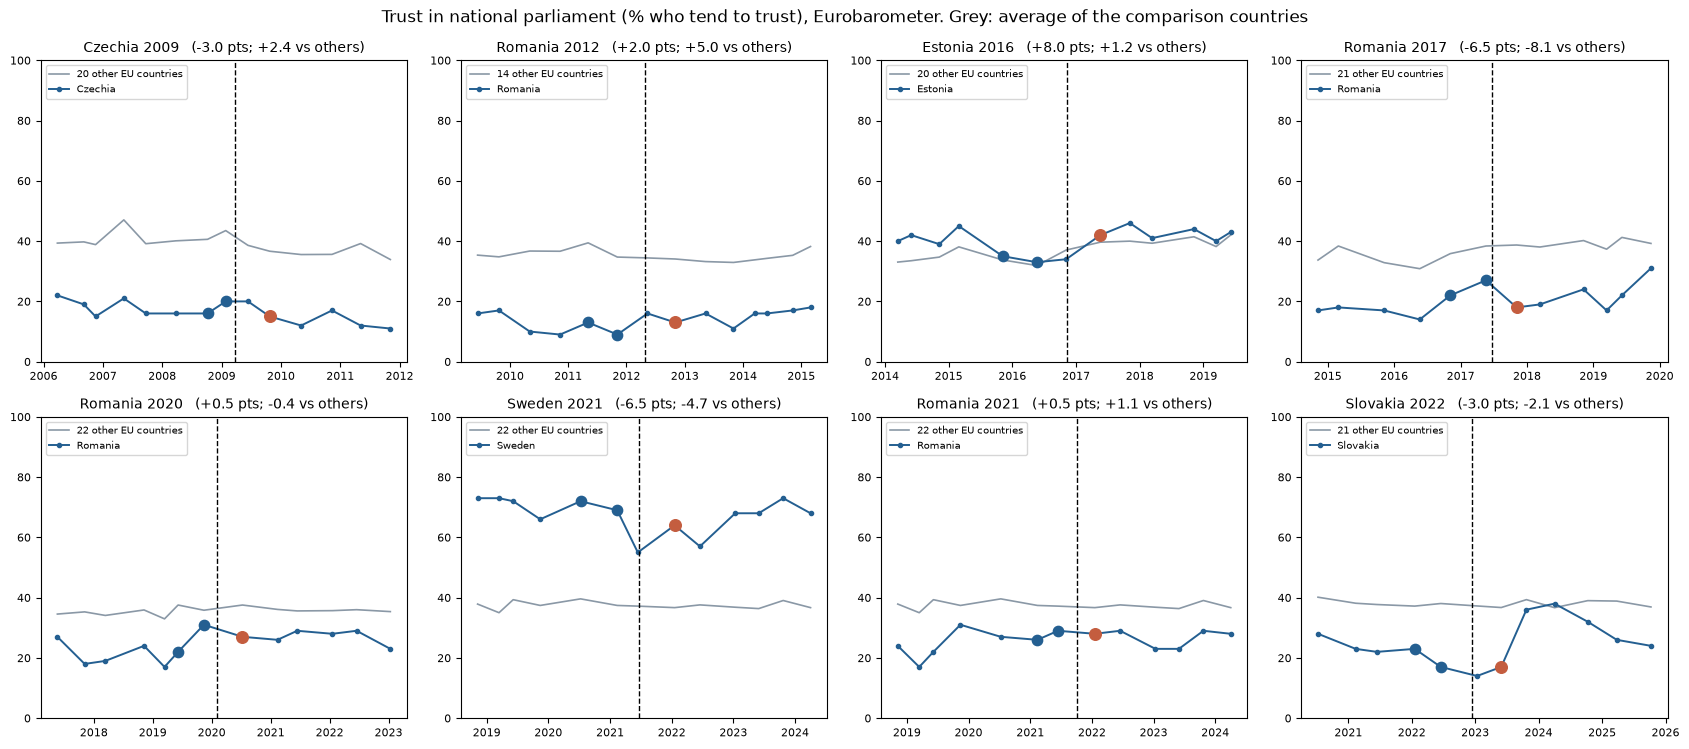

In [3]:
eb = load_waves()
par = eb[eb.institution == 'National parliament']

fig, axes = plt.subplots(2, 4, figsize=(17, 7.6))
for ax, r in zip(axes.flat, clean.itertuples()):
    code_ = ISO3_TO_EB[r.iso3]
    ev = r.event_date
    lo, hi = ev - pd.DateOffset(years=3), ev + pd.DateOffset(years=3)
    c = par[(par.country_code == code_) & par.start.between(lo, hi)].sort_values('start')
    group = r.parl_comparison_group.split(';')  # the same countries the numbers are compared with
    g = (par[par.country_code.isin(group) & par.start.between(lo, hi)].groupby('wave')
         .agg(start=('start', 'min'), trust=('trust', 'mean')).sort_values('start'))
    ax.plot(g.start, g.trust, color=GREY, lw=1.2, label=f'{len(group)} other EU countries')
    ax.plot(c.start, c.trust, color=BLUE, marker='o', ms=3, lw=1.4, label=COUNTRY[r.iso3])
    pre = set(r.parl_pre_waves.split('; '))
    p = c[c.start.dt.strftime('%Y-%m-%d').isin(pre)]
    ax.scatter(p.start, p.trust, s=55, color=BLUE, zorder=3)
    q = c[c.start == pd.Timestamp(r.parl_post_wave_start)]
    ax.scatter(q.start, q.trust, s=70, color=RED, zorder=3)
    ax.axvline(ev, color='black', ls='--', lw=1)
    ax.set_title(f"{r.episode}   ({r.parl_change_pp:+.1f} pts; {getattr(r, CHANGE):+.1f} vs others)", fontsize=10)
    ax.set_ylim(0, 100)
    ax.tick_params(labelsize=8)
    ax.legend(fontsize=7, loc='upper left')
fig.suptitle('Trust in national parliament (% who tend to trust), Eurobarometer. Grey: average of the comparison countries', fontsize=12)
plt.tight_layout()
plt.show()

## 4. How big were the changes?

Each dot is one episode: the change in trust from before to after, **minus** the change in other EU countries. The grey band is ±3 points, the usual sampling noise of a single survey. Filled blue dots are the 8 clean episodes; hollow grey dots are the three where an election intervenes; the red diamond is France, held out.

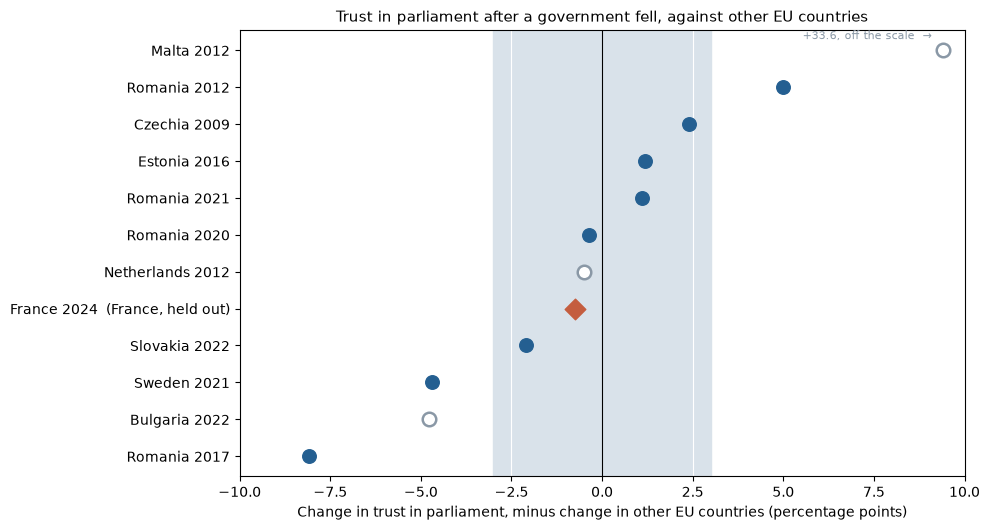

8 clean episodes: median +0.4, range -8.1 to +5.0.
Within the ±3 noise band: 5 of 8.  Outside it: Romania 2012 (+5.0), Romania 2017 (-8.1), Sweden 2021 (-4.7)
Up: 4, down: 4.


In [4]:
rows = pd.concat([clean.assign(kind='clean'), broad.assign(kind='broad'), pd.DataFrame([france]).assign(kind='france')])
rows = rows.dropna(subset=[CHANGE]).sort_values(CHANGE).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5.4))
ax.axvspan(-3, 3, color=LIGHT, zorder=0)
ax.axvline(0, color='black', lw=0.8)
XMAX = 10
for y, r in rows.iterrows():
    x = min(r[CHANGE], XMAX - 0.6)
    if r.kind == 'clean':
        ax.scatter(x, y, s=95, color=BLUE, zorder=3)
    elif r.kind == 'broad':
        ax.scatter(x, y, s=95, facecolors='white', edgecolors=GREY, linewidths=1.8, zorder=3)
    else:
        ax.scatter(x, y, s=110, marker='D', color=RED, zorder=3)
    if r[CHANGE] > XMAX - 0.6:  # off the scale: keep the other points readable
        ax.annotate(f"{r[CHANGE]:+.1f}, off the scale  →", (x, y), textcoords='offset points', xytext=(-8, 8), ha='right', fontsize=8, color=GREY)
ax.set_xlim(-10, XMAX)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{r.episode}{'  (France, held out)' if r.kind == 'france' else ''}" for r in rows.itertuples()])
ax.set_xlabel('Change in trust in parliament, minus change in other EU countries (percentage points)')
ax.set_title('Trust in parliament after a government fell, against other EU countries', fontsize=11)
ax.grid(axis='x', color='white')
plt.tight_layout()
plt.show()

v = clean[CHANGE]
print(f"8 clean episodes: median {v.median():+.1f}, range {v.min():+.1f} to {v.max():+.1f}.")
print(f"Within the ±3 noise band: {int((v.abs() <= 3).sum())} of {len(v)}.  Outside it: " +
      ', '.join(f"{r.episode} ({getattr(r, CHANGE):+.1f})" for r in clean[v.abs() > 3].itertuples()))
print(f"Up: {int((v > 0).sum())}, down: {int((v < 0).sum())}.")

## 5. Do the starting conditions line up with the change?

Each panel plots one sign of a **weak government**, known on the day it fell, against the change in trust: how far it was from a majority, how much it leaned on the prime minister's party, how strong the biggest opposition party was, how far apart its parties are on the left-right scale, how unstable the previous two years were, and how long the cabinet had lasted. Trust before and unemployment are added as background. How long the crisis then lasted is an outcome (section 6), not an input. The red diamond is France. With 8 points there is **no fitted line**, only the points and a rank correlation. Seat shares are those when the cabinet formed.

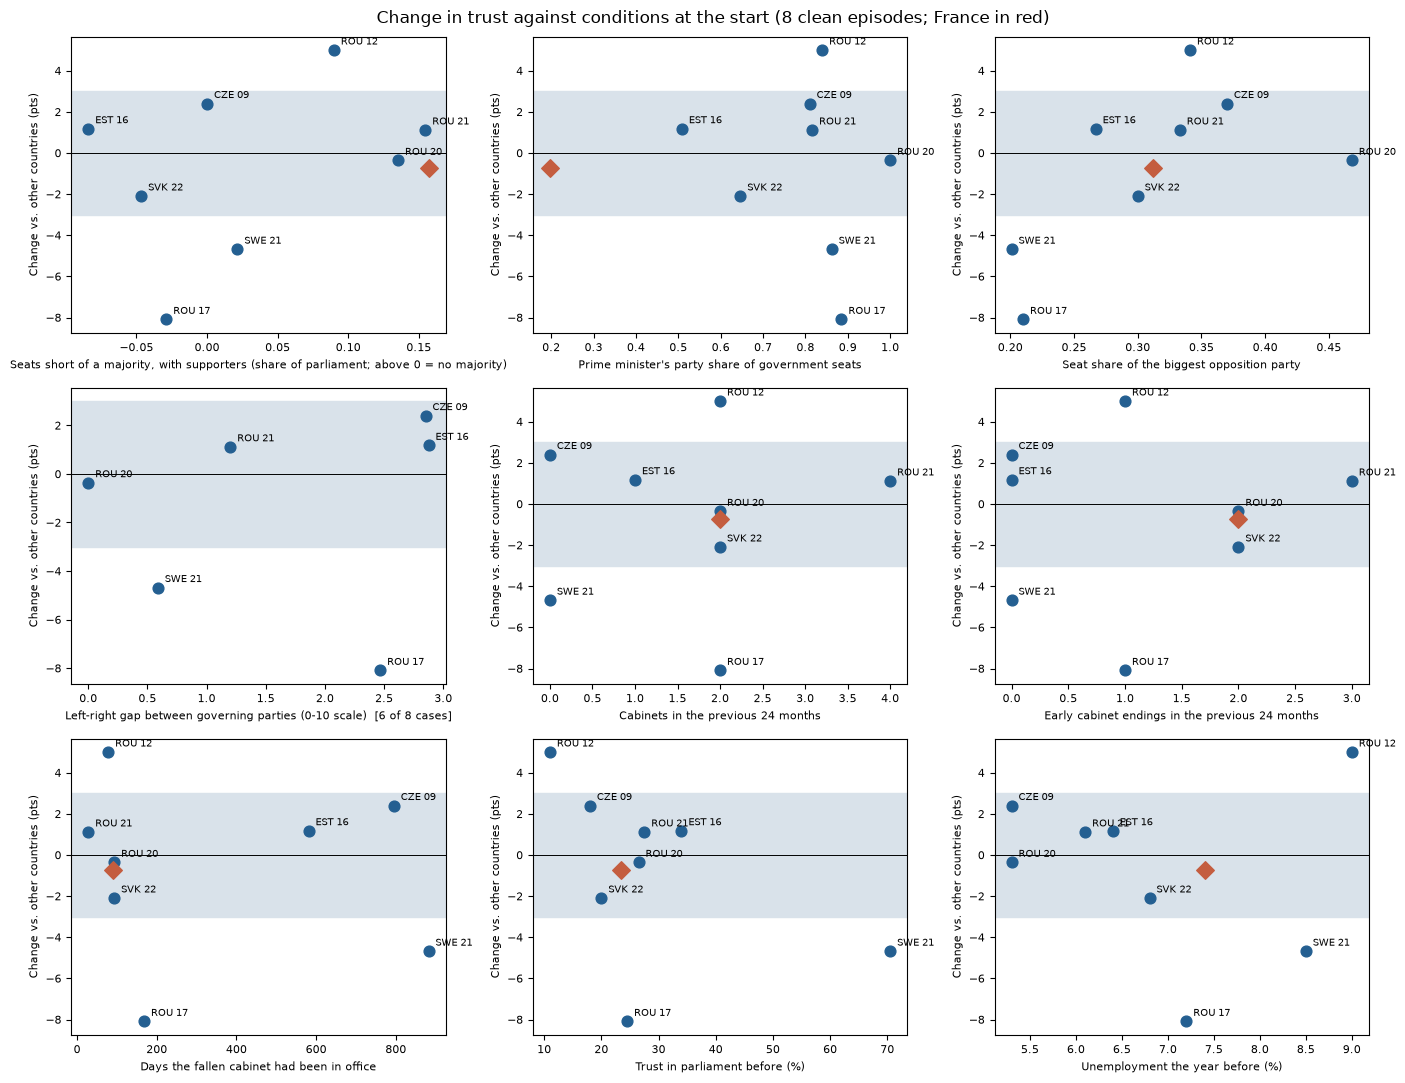

,Cases,Rank correlation
Variable,,
"Seats short of a majority, with supporters (share of parliament; above 0 = no majority)",8,+0.17
Prime minister's party share of government seats,8,-0.43
Seat share of the biggest opposition party,8,+0.62
Left-right gap between governing parties (0-10 scale),6,+0.48
Cabinets in the previous 24 months,8,-0.06
Early cabinet endings in the previous 24 months,8,-0.15
Days the fallen cabinet had been in office,8,-0.25
Trust in parliament before (%),8,-0.45
Unemployment the year before (%),8,-0.18


In [5]:
PANELS = [
    ('majority_shortfall_with_support', 'Seats short of a majority, with supporters (share of parliament; above 0 = no majority)'),
    ('pm_party_share_of_government', "Prime minister's party share of government seats"),
    ('largest_opposition_party_seat_share', 'Seat share of the biggest opposition party'),
    ('coalition_lr_spread', 'Left-right gap between governing parties (0-10 scale)'),
    ('cabinets_24m_before', 'Cabinets in the previous 24 months'),
    ('early_endings_24m_before', 'Early cabinet endings in the previous 24 months'),
    ('ending_cabinet_age_days', 'Days the fallen cabinet had been in office'),
    ('parl_pre_trust_pct', 'Trust in parliament before (%)'),
    ('unemployment_pct', 'Unemployment the year before (%)'),
]
CRITICAL = {5: 1.0, 6: 0.886, 7: 0.786, 8: 0.738}  # Spearman, two-sided 5%, by number of cases
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
rho = []
for ax, (col, label) in zip(axes.flat, PANELS):
    ax.axhspan(-3, 3, color=LIGHT, zorder=0)
    ax.axhline(0, color='black', lw=0.7)
    ax.scatter(clean[col], clean[CHANGE], s=60, color=BLUE, zorder=3)
    n_cases = int(clean[[col, CHANGE]].notna().all(axis=1).sum())
    for r in clean.itertuples():
        if pd.isna(getattr(r, col)):
            continue
        ax.annotate(r.short, (getattr(r, col), getattr(r, CHANGE)), textcoords='offset points', xytext=(5, 4), fontsize=7)
    if pd.notna(france[col]) and pd.notna(france[CHANGE]):
        ax.scatter(france[col], france[CHANGE], s=80, marker='D', color=RED, zorder=4)
    ax.set_xlabel(label + (f'  [{n_cases} of 8 cases]' if n_cases < 8 else ''), fontsize=8)
    ax.set_ylabel('Change vs. other countries (pts)', fontsize=8)
    ax.tick_params(labelsize=8)
    # Spearman rank correlation = Pearson correlation of the ranks
    rho.append({'Variable': label, 'Cases': n_cases, 'Rank correlation': clean[col].rank().corr(clean[CHANGE].rank())})
fig.suptitle('Change in trust against conditions at the start (8 clean episodes; France in red)', fontsize=12)
plt.tight_layout()
plt.show()
pd.DataFrame(rho).set_index('Variable').style.format({'Rank correlation': '{:+.2f}', 'Cases': '{:.0f}'})

**How to read the correlations.** With 8 cases a rank correlation has to be beyond about **±0.74** to stand out from chance at the usual 5% level; with 6 cases, about ±0.89. Smaller values mean nothing can be said either way. The *Cases* column shows how many episodes had the data. Because several variables are tried, even a value past the line would need a second look.

In [6]:
strong = [r for r in rho if r['Cases'] >= 5 and abs(r['Rank correlation']) >= CRITICAL[r['Cases']]]
if strong:
    print('Past the chance line:', '; '.join(f"{r['Variable']} ({r['Rank correlation']:+.2f})" for r in strong))
else:
    print('No variable passes its chance line. With so few cases, none of these signs separates the larger falls from the smaller ones.')

No variable passes its chance line. With so few cases, none of these signs separates the larger falls from the smaller ones.


## 6. Other things that moved

How long the crisis lasted, trust in government and in parties, turnout and the number of parties at the **next** parliamentary election, and the radical vote. Blanks mean the data do not exist yet (for example no later election). The next election can be years after the event, so these are weaker evidence than the trust figures. Radical vote excludes parties that PopuList marks as borderline.

In [7]:
o = pd.DataFrame({
    'Episode': clean.episode,
    'Days until a normal cabinet': clean.days_until_non_caretaker_cabinet,
    'Government trust vs. others': clean.gov_change_beyond_comparison_pp,
    'Party trust vs. others': clean.parties_change_beyond_comparison_pp,
    'Next election': clean.next_election,
    'Turnout change': clean.turnout_change_pp,
    'Effective parties change': clean.effective_parties_change,
    'Radical vote change': clean.radical_change_pp,
}).set_index('Episode')
o.style.format({c: ('{:.0f}' if c == 'Days until a normal cabinet' else '{:+.1f}') for c in o.columns if c != 'Next election'}, na_rep='–')

,Days until a normal cabinet,Government trust vs. others,Party trust vs. others,Next election,Turnout change,Effective parties change,Radical vote change
Episode,,,,,,,
Czechia 2009,461,+21.3,+3.3,2010-05-29,-1.9,+2.7,-1.5
Romania 2012,10,+11.9,-0.5,2012-12-09,+1.2,-1.4,-1.9
Estonia 2016,14,-0.8,-4.5,2019-03-03,-0.6,+0.0,+9.6
Romania 2017,8,-12.8,-5.5,2020-12-06,-7.8,+1.6,+8.6
Romania 2020,38,+4.9,-0.8,2020-12-06,-7.8,+1.6,+8.6
Sweden 2021,18,+3.3,-7.3,2022-09-11,-3.0,-0.4,+3.0
Romania 2021,51,-2.3,+2.2,2024-12-01,+16.3,+2.0,+22.7
Slovakia 2022,314,+0.5,+2.0,2023-09-30,+2.7,-0.3,-10.4


## 7. France next to the eight

France's Barnier government fell on 4 December 2024. Here is France on the same starting conditions, against the range of the 8. *Inside* means France sits within the lowest and highest of the eight. This is a comparison, **not a forecast** for France.

In [8]:
rows = []
for col, label in PANELS:
    lo, hi = clean[col].min(), clean[col].max()
    f = france[col]
    if pd.isna(f):
        rows.append({'Starting condition': label, 'France': f, 'Lowest of 8': lo, 'Highest of 8': hi, 'Where France sits': 'not available (a governing party has no CHES rating)'})
        continue
    where = 'inside' if lo <= f <= hi else ('below' if f < lo else 'above')
    rank = int((clean[col] < f).sum()) + 1
    rows.append({'Starting condition': label, 'France': f, 'Lowest of 8': lo, 'Highest of 8': hi,
                 'Where France sits': f"{where} (would rank {rank} of 9 from the bottom)"})
cmp_ = pd.DataFrame(rows).set_index('Starting condition')
display(cmp_.style.format({'France': '{:.2f}', 'Lowest of 8': '{:.2f}', 'Highest of 8': '{:.2f}'}, na_rep='–'))
print(f"France, observed: trust {france.parl_pre_trust_pct:.1f}% before, {france.parl_post_trust_pct:.1f}% after "
      f"({france.parl_change_pp:+.1f} pts; {france[CHANGE]:+.1f} vs. other countries). "
      f"The 8 clean episodes ranged from {clean[CHANGE].min():+.1f} to {clean[CHANGE].max():+.1f}.")

,France,Lowest of 8,Highest of 8,Where France sits
Starting condition,,,,
"Seats short of a majority, with supporters (share of parliament; above 0 = no majority)",0.16,-0.08,0.15,above (would rank 9 of 9 from the bottom)
Prime minister's party share of government seats,0.20,0.51,1.00,below (would rank 1 of 9 from the bottom)
Seat share of the biggest opposition party,0.31,0.20,0.47,inside (would rank 5 of 9 from the bottom)
Left-right gap between governing parties (0-10 scale),–,0.00,2.88,not available (a governing party has no CHES rating)
Cabinets in the previous 24 months,2.00,0.00,4.00,inside (would rank 4 of 9 from the bottom)
Early cabinet endings in the previous 24 months,2.00,0.00,3.00,inside (would rank 6 of 9 from the bottom)
Days the fallen cabinet had been in office,90.00,28.00,882.00,inside (would rank 3 of 9 from the bottom)
Trust in parliament before (%),23.50,11.00,70.50,inside (would rank 4 of 9 from the bottom)
Unemployment the year before (%),7.40,5.30,9.00,inside (would rank 7 of 9 from the bottom)


France, observed: trust 23.5% before, 24.0% after (+0.5 pts; -0.7 vs. other countries). The 8 clean episodes ranged from -8.1 to +5.0.


## 8. What this says, and what it does not

In [9]:
from IPython.display import Markdown
v = clean[CHANGE]
big = clean[v.abs() > 3]
low = clean[clean.parl_pre_trust_pct < 30]
low_names = ', '.join(low.episode)
lines = [
    f"- **Most of the eight barely moved.** {int((v.abs() <= 3).sum())} of 8 changed by 3 points or less against other EU countries, which is inside normal survey noise. The median is {v.median():+.1f}.",
    "- **" + str(len(big)) + " stand out:** " + ', '.join(f"{r.episode} ({getattr(r, CHANGE):+.1f})" for r in big.itertuples()) + ". "
    + ' and '.join(r.episode for r in big[big[CHANGE] < 0].itertuples()) + " fell; " + ' and '.join(r.episode for r in big[big[CHANGE] > 0].itertuples()) + " rose.",
    "- **The direction is mixed.** " + f"{int((v > 0).sum())} rose and {int((v < 0).sum())} fell, so a government falling does not by itself mean trust falls in the following months.",
    f"- **France is inside the range.** Its observed change ({france[CHANGE]:+.1f}) is within what the eight show. Its starting trust ({france.parl_pre_trust_pct:.1f}%) is low; {len(low)} of the eight also started below 30% ({low_names}).",
    ("- **No sign of a weak government lines up with the change** (section 5), though 8 cases could not show a weak link." if not strong
     else "- **Some signs line up with the change** (section 5), but with 8 cases and several variables tried this needs a second look."),
]
Markdown('\n'.join(lines))

- **Most of the eight barely moved.** 5 of 8 changed by 3 points or less against other EU countries, which is inside normal survey noise. The median is +0.4.
- **3 stand out:** Romania 2012 (+5.0), Romania 2017 (-8.1), Sweden 2021 (-4.7). Romania 2017 and Sweden 2021 fell; Romania 2012 rose.
- **The direction is mixed.** 4 rose and 4 fell, so a government falling does not by itself mean trust falls in the following months.
- **France is inside the range.** Its observed change (-0.7) is within what the eight show. Its starting trust (23.5%) is low; 6 of the eight also started below 30% (Czechia 2009, Romania 2012, Romania 2017, Romania 2020, Romania 2021, Slovakia 2022).
- **No sign of a weak government lines up with the change** (section 5), though 8 cases could not show a weak link.

**What it cannot show**

- **No cause.** A change in trust after a government fell does not prove the fall caused it. Other events, the economy and the surveys' own noise all play a part.
- **Few and not independent.** 8 cases in 5 countries; 4 are Romanian. A few more or fewer cases would change the picture.
- **Overlaps remain.** Czechia 2009 and Romania 2012 sit in economic crises, Romania 2020 includes the start of COVID, and Romania 2020 and Sweden 2021 saw the same prime minister return. The *flags* column in section 2 records them.
- **Government base is measured at formation.** Seat shares are the cabinet's when it formed, not when it fell. Supporting parties are coded by PPEG without a coalition agreement, and that coding is probably incomplete in some countries.
- **Clean is a narrow test.** It rules out elections and other reviewed crises only, not every shock.
- **The 3 to 9 month window** was fixed in advance. A different window would give different numbers, and Eurobarometer surveys come twice a year.
- **Records still to check.** Official vote records for Romania 2012 and 2021 are not yet retrieved, and Orban's 2020 return date needs confirming.

## Part 2 · A larger set of S1 cases

Eight episodes are too few to see a pattern. PPEG lists every cabinet that ended early. For 45 of them, coded as ended by **dissension** (a coalition falling apart), I researched what happened and **the day the government fell**. In **20** the government lost its majority, lost a vote or resigned. The other 25 were set aside: reshuffles, a party leaving while the government kept its majority, scandal resignations (counted under S3), Cyprus (a presidential system, where a government cannot fall), and 5 that could not be dated.

That gives **34 S1 episodes**: the 14 reviewed ones (France held out) and the 20 researched ones. **31 have a usable trust window and 19 are clean** (no election or other ending before the "after" survey).

**Same variables as Part 1:** the same inputs, controls and trust outputs, built the same way. The researched dates come from news and encyclopedia sources and **none has yet been checked against an official record** (the sources and a confidence rating are in `data/reference/s1_researched_dates.csv`). The comparison countries are those with no early ending of any kind in the same period, so a reviewed episode's number can differ slightly from Part 1.

In [10]:
b = pd.read_csv(ROOT / 'data/processed/s1_broad_episode_dataset.csv')
b['flags'] = b['flags'].fillna('')
b['event_date'] = pd.to_datetime(b.event_date)
b['episode'] = [f"{COUNTRY.get(r.iso3, r.iso3)} {r.event_date.year}" for r in b.itertuples()]
bc = b[b.sample_group == 'clean'].reset_index(drop=True)
bfrance = b[b.sample_group == 'held_out'].iloc[0]
GROUPS = {'PPEG: cabinet dissension': 'Coalition broke up (researched)', 'government collapse': 'Reviewed episodes'}
b['cause'] = b.case_group.map(GROUPS)
bc = b[b.sample_group == 'clean'].reset_index(drop=True)
tab = (b.groupby(['cause', 'sample_group']).size().unstack(fill_value=0)
        .reindex(columns=['clean', 'broad_only', 'no_post_wave', 'held_out'], fill_value=0))
tab['all'] = tab.sum(axis=1)
tab = tab.sort_values('all', ascending=False)
tab.loc['All'] = tab.sum()
print(f"{len(b)} early endings; {len(bc)} are clean (no election or other ending before the 'after' survey) in {bc.iso3.nunique()} countries.")
tab.rename(columns={'clean': 'Clean (used below)', 'broad_only': 'Election or other ending in between', 'no_post_wave': 'No "after" survey yet', 'held_out': 'France (held out)'})

34 early endings; 19 are clean (no election or other ending before the 'after' survey) in 11 countries.


sample_group,Clean (used below),Election or other ending in between,"No ""after"" survey yet",France (held out),all
cause,,,,,
Coalition broke up (researched),12,8,0,0,20
Reviewed episodes,7,4,2,1,14
All,19,12,2,1,34


## 9. When each government fell, and when the crisis ended

**Fell** is the day the government lost its majority, lost a vote or resigned (the first of these). **New cabinet** is the day the next cabinet took office, which can be a caretaker. **Full government** is the day the first cabinet not coded expert or caretaker took office: the end of the crisis in PPEG terms. A blank means PPEG has no later cabinet yet.

In [11]:
d9 = b.sort_values(['iso3', 'event_date']).copy()
d9['Fell'] = d9.event_date.dt.strftime('%d %b %Y')
d9['New cabinet'] = pd.to_datetime(d9.successor_start).dt.strftime('%d %b %Y')
d9['Full government'] = pd.to_datetime(d9.full_government_start).dt.strftime('%d %b %Y')
tbl = pd.DataFrame({
    'Episode': d9.episode.values,
    'Fell': d9.Fell.values,
    'How': np.where(d9.date_basis == 'researched', d9['flags'].astype(str), d9.event_type.map(HOW).astype(str)),
    'New cabinet': d9['New cabinet'].values,
    'Days': d9.days_to_successor.values,
    'Full government': d9['Full government'].values,
    'Days to full government': d9.days_until_non_caretaker_cabinet.values,
    'Date from': d9.date_basis.values,
    'Window': d9.sample_group.values,
}).set_index('Episode')
tbl.style.format({'Days': '{:.0f}', 'Days to full government': '{:.0f}'}, na_rep='–')

,Fell,How,New cabinet,Days,Full government,Days to full government,Date from,Window
Episode,,,,,,,,
BEL 2018,09 Dec 2018,"coalition partner left, minority",21 Dec 2018,12,17 Mar 2020,464,researched,clean
Bulgaria 2022,22 Jun 2022,lost a no-confidence vote,02 Aug 2022,41,06 Jun 2023,349,verified,broad_only
Czechia 2009,24 Mar 2009,lost a no-confidence vote,08 May 2009,45,28 Jun 2010,461,verified,clean
DEU 2024,06 Nov 2024,"coalition partner left, minority; lost confidence vote",07 Nov 2024,1,06 May 2025,181,researched,broad_only
Estonia 2016,09 Nov 2016,lost a no-confidence vote,23 Nov 2016,14,23 Nov 2016,14,verified,clean
Estonia 2022,03 Jun 2022,"coalition collapsed, partner dismissed",18 Jul 2022,45,18 Jul 2022,45,researched,clean
France 2024,04 Dec 2024,lost a no-confidence vote,13 Dec 2024,9,13 Dec 2024,9,verified,held_out
HRV 2017,27 Apr 2017,coalition partner dismissed and left,09 Jun 2017,43,09 Jun 2017,43,researched,clean
HUN 2008,30 Apr 2008,"coalition partner left, minority",14 Apr 2009,349,29 May 2010,759,researched,clean


## 10. How big were the changes, across all the clean cases?

Each bar counts cases by their change in trust in parliament, minus the change in other EU countries. The grey band is ±3 points, the usual sampling noise of one survey. The line below the chart gives the median with a range that allows for cases from the same country resembling each other (a country-by-country bootstrap).

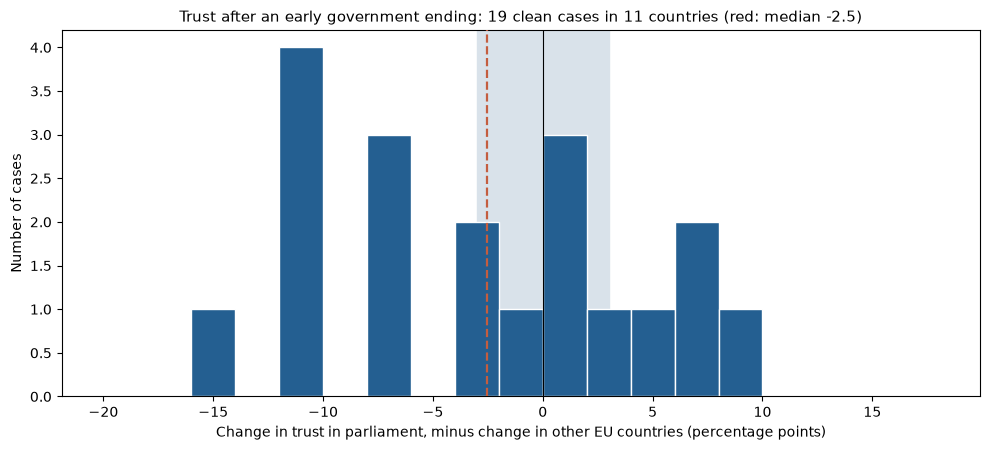

Median -2.5 points (95% range -7.8 to +2.0, resampling countries). Mean -2.9.
Within the ±3 band: 6 of 19 (32%).  Fell by more than 3: 9.  Rose by more than 3: 4.


In [12]:
v = bc[CHANGE]
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.axvspan(-3, 3, color=LIGHT, zorder=0)
ax.hist(v, bins=np.arange(-20, 20, 2), color=BLUE, edgecolor='white', zorder=2)
ax.axvline(0, color='black', lw=0.8)
ax.axvline(v.median(), color=RED, lw=1.6, ls='--', zorder=3)
ax.set_xlabel('Change in trust in parliament, minus change in other EU countries (percentage points)')
ax.set_ylabel('Number of cases')
ax.set_title(f'Trust after an early government ending: {len(v)} clean cases in {bc.iso3.nunique()} countries (red: median {v.median():+.1f})', fontsize=11)
plt.tight_layout()
plt.show()

rng = np.random.default_rng(0)
countries = bc.iso3.unique()
meds = []
for _ in range(3000):
    pick = rng.choice(countries, len(countries))
    meds.append(np.median(np.concatenate([bc.loc[bc.iso3 == c, CHANGE].values for c in pick])))
lo, hi = np.percentile(meds, [2.5, 97.5])
print(f"Median {v.median():+.1f} points (95% range {lo:+.1f} to {hi:+.1f}, resampling countries). Mean {v.mean():+.1f}.")
print(f"Within the ±3 band: {int((v.abs() <= 3).sum())} of {len(v)} ({(v.abs() <= 3).mean():.0%}).  Fell by more than 3: {int((v < -3).sum())}.  Rose by more than 3: {int((v > 3).sum())}.")

### By how the government ended

In [13]:
by = bc.groupby('cause')[CHANGE].agg(Cases='count', Median='median', Mean='mean', Fell_over_3=lambda x: int((x < -3).sum()), Rose_over_3=lambda x: int((x > 3).sum()))
by = by.sort_values('Cases', ascending=False)
by.style.format({'Median': '{:+.1f}', 'Mean': '{:+.1f}'})

,Cases,Median,Mean,Fell_over_3,Rose_over_3
cause,,,,,
Coalition broke up (researched),12,-7.1,-3.6,7,3
Reviewed episodes,7,-1.4,-1.7,2,1


## 11. Do signs of a weak government line up with the change?

With about 19 cases a correlation can mean something, but **the more variables you try, the more likely one looks good by luck**. The table gives each rank correlation, how often a correlation that large appears when the changes are shuffled at random (the *chance* column), and whether it clears the bar that corrects for trying 13 variables at once (**0.05 divided by 13, about 0.004**).

In [14]:
INPUTS = [
    ('majority_shortfall_with_support', 'Seats short of a majority, with supporters'),
    ('pm_party_share_of_government', "Prime minister's party share of government seats"),
    ('largest_opposition_party_seat_share', 'Seat share of the biggest opposition party'),
    ('coalition_lr_spread', 'Left-right gap between governing parties'),
    ('cabinets_24m_before', 'Cabinets in the previous 24 months'),
    ('early_endings_24m_before', 'Early cabinet endings in the previous 24 months'),
    ('ending_cabinet_age_days', 'Days the ended cabinet had been in office'),
    ('effective_parties_prev', 'Number of parties in parliament at the last election'),
    ('parl_pre_trust_pct', 'Trust in parliament before (%)'),
    ('unemployment_pct', 'Unemployment the year before (%)'),
    ('gdp_growth_pct', 'GDP growth the year before (%)'),
    ('inflation_pct', 'Inflation the year before (%)'),
    ('radical_prev_pct', 'Radical vote at the last election (%)'),
]
rng = np.random.default_rng(1)
rows = []
for col, label in INPUTS:
    x = bc[[col, CHANGE]].dropna()
    rx, ry = x[col].rank().values, x[CHANGE].rank().values
    r = np.corrcoef(rx, ry)[0, 1]
    perm = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(4000)])
    rows.append({'Sign of weakness': label, 'Cases': len(x), 'Rank correlation': r, 'Chance': (np.abs(perm) >= abs(r)).mean()})
corr = pd.DataFrame(rows).set_index('Sign of weakness')
corr['Clears the bar?'] = np.where(corr['Chance'] < 0.05 / len(INPUTS), 'yes', 'no')
corr.style.format({'Rank correlation': '{:+.2f}', 'Chance': '{:.3f}'})

,Cases,Rank correlation,Chance,Clears the bar?
Sign of weakness,,,,
"Seats short of a majority, with supporters",19,-0.01,0.964,no
Prime minister's party share of government seats,18,+0.27,0.278,no
Seat share of the biggest opposition party,19,+0.18,0.454,no
Left-right gap between governing parties,14,+0.26,0.375,no
Cabinets in the previous 24 months,19,+0.10,0.676,no
Early cabinet endings in the previous 24 months,19,+0.13,0.581,no
Days the ended cabinet had been in office,19,-0.13,0.597,no
Number of parties in parliament at the last election,19,-0.15,0.528,no
Trust in parliament before (%),19,-0.40,0.086,no


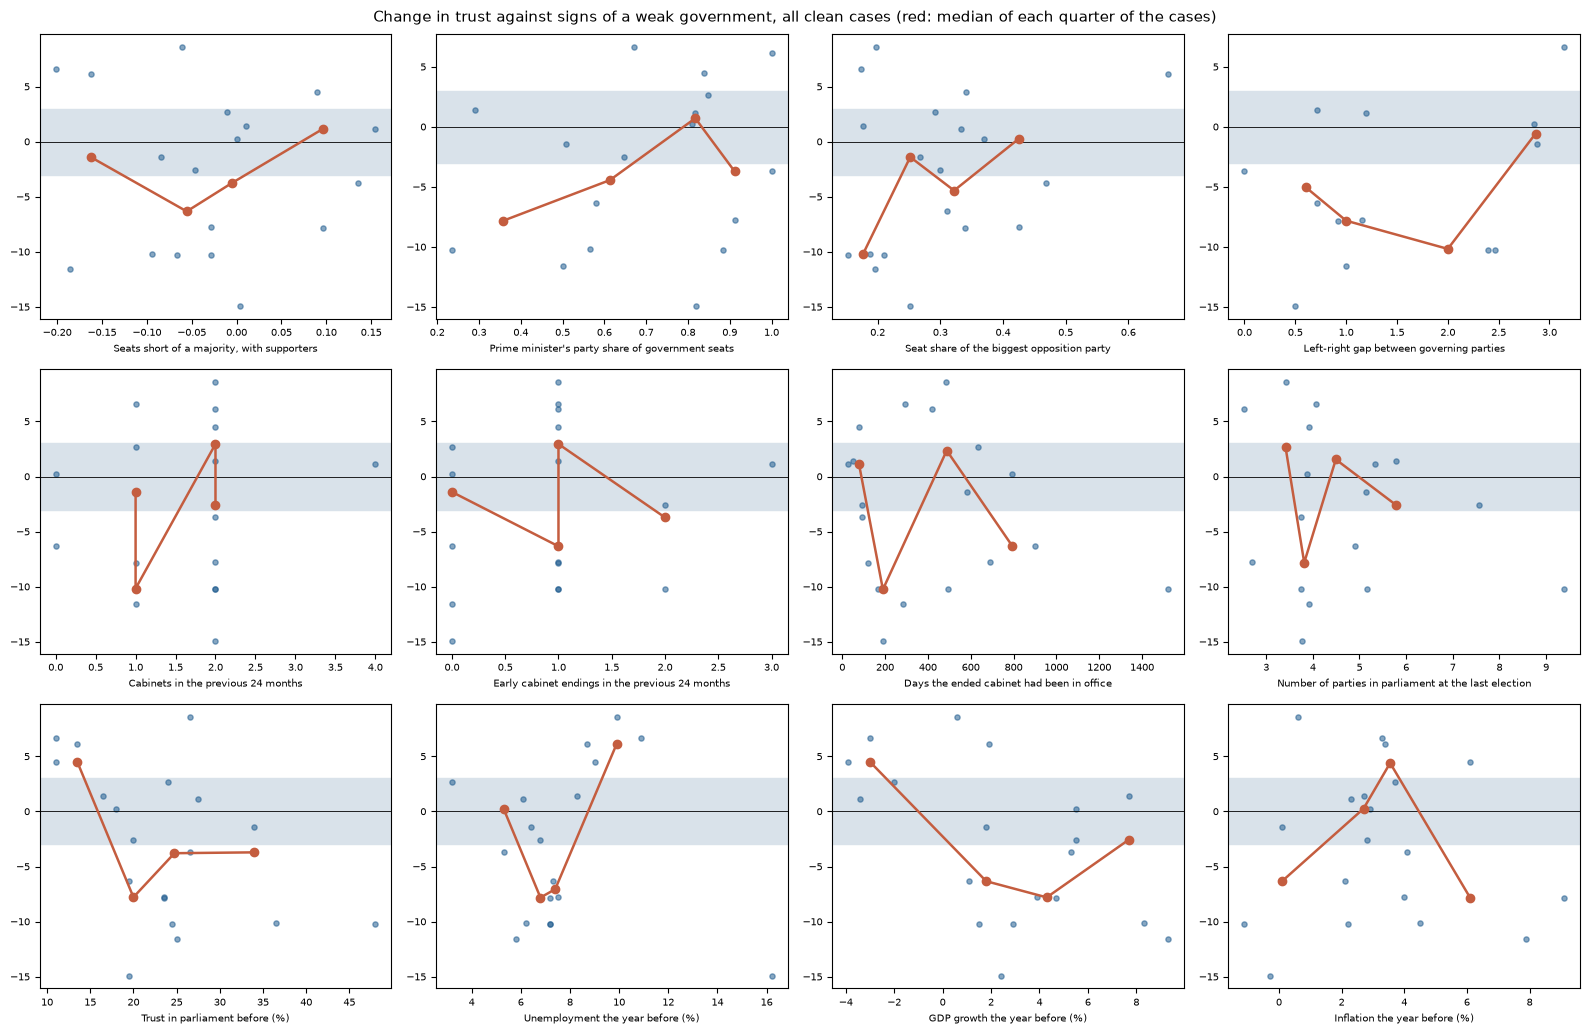

In [15]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10.5))
for ax, (col, label) in zip(axes.flat, INPUTS[:12]):
    x = bc[[col, CHANGE]].dropna()
    ax.axhspan(-3, 3, color=LIGHT, zorder=0)
    ax.scatter(x[col], x[CHANGE], s=14, color=BLUE, alpha=0.55, zorder=2)
    q = pd.qcut(x[col].rank(method='first'), 4, labels=False)
    med = x.groupby(q).agg(x=(col, 'median'), y=(CHANGE, 'median'))
    ax.plot(med.x, med.y, color=RED, marker='o', lw=1.8, zorder=3)
    ax.axhline(0, color='black', lw=0.6)
    ax.set_xlabel(label, fontsize=7.5)
    ax.tick_params(labelsize=7)
fig.suptitle('Change in trust against signs of a weak government, all clean cases (red: median of each quarter of the cases)', fontsize=11)
plt.tight_layout()
plt.show()

### Do the leads hold up?

Any sign that stands out is re-tested here (if none does, the cell says so). Each lead is re-tested **without the financial-crisis years**, on **later years only**, on **approximate-date cases only** and on **verified-date cases only** (very few), and with **one country left out at a time**.

In [16]:
lead_cols = {label: col for col, label in INPUTS}
leads = [lead_cols[l] for l in corr[corr['Chance'] < 0.01].index]
c2 = bc.assign(year=bc.event_date.dt.year)
SETS = [('All clean cases', c2),
        ('Without 2006-2010 (financial-crisis years)', c2[~c2.year.between(2006, 2010)]),
        ('2011 and later only', c2[c2.year >= 2011]),
        ('Researched dates only', c2[c2.date_basis == 'researched']),
        ('Verified dates only', c2[c2.date_basis == 'verified'])]
rng = np.random.default_rng(5)
def spearman(x, col):
    x = x[[col, CHANGE]].dropna()
    if len(x) < 5:
        return len(x), np.nan, np.nan
    rx, ry = x[col].rank().values, x[CHANGE].rank().values
    r = np.corrcoef(rx, ry)[0, 1]
    perm = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(5000)])
    return len(x), r, (np.abs(perm) >= abs(r)).mean()
rows = []
for col in leads:
    for name, sub in SETS:
        n, r, p = spearman(sub, col)
        rows.append({'Lead': {c: l for c, l in INPUTS}[col], 'Cases kept': name, 'Cases': n, 'Rank correlation': r, 'Chance': p})
    loo = []
    for k in c2.iso3.unique():
        z = c2[c2.iso3 != k][[col, CHANGE]].dropna()
        loo.append(z[col].rank().corr(z[CHANGE].rank()))
    rows.append({'Lead': {c: l for c, l in INPUTS}[col], 'Cases kept': f'Leaving out one country (range over {len(loo)} runs)', 'Cases': np.nan,
                 'Rank correlation': np.nan, 'Chance': np.nan, 'Low': min(loo), 'High': max(loo)})
if not rows:
    print('No sign of weakness has a chance below 0.01, so there is no lead to re-test.')
else:
    rob = pd.DataFrame(rows).set_index(['Lead', 'Cases kept'])
    display(rob.style.format({'Cases': '{:.0f}', 'Rank correlation': '{:+.2f}', 'Chance': '{:.3f}', 'Low': '{:+.2f}', 'High': '{:+.2f}'}, na_rep=''))

No sign of weakness has a chance below 0.01, so there is no lead to re-test.


## 12. France next to the larger set

Where France sits among the clean cases on each starting condition (a percentile: 50% means France is in the middle).

In [17]:
rows = []
for col, label in INPUTS:
    x = bc[col].dropna()
    f = bfrance[col]
    rows.append({'Starting condition': label, 'France': f, 'Median of cases': x.median(),
                 'France sits at the percentile': (x < f).mean() * 100 if pd.notna(f) else np.nan})
fr = pd.DataFrame(rows).set_index('Starting condition')
fr.style.format({'France': '{:.2f}', 'Median of cases': '{:.2f}', 'France sits at the percentile': '{:.0f}%'}, na_rep='–')

,France,Median of cases,France sits at the percentile
Starting condition,,,
"Seats short of a majority, with supporters",0.16,-0.03,100%
Prime minister's party share of government seats,0.20,0.74,0%
Seat share of the biggest opposition party,0.31,0.29,63%
Left-right gap between governing parties,–,1.18,–
Cabinets in the previous 24 months,2.00,2.00,42%
Early cabinet endings in the previous 24 months,2.00,1.00,79%
Days the ended cabinet had been in office,90.00,295.00,16%
Number of parties in parliament at the last election,–,3.92,–
Trust in parliament before (%),23.50,23.50,42%


## 13. What the larger set says

In [18]:
from IPython.display import Markdown
v = bc[CHANGE]
clears = corr[corr['Clears the bar?'] == 'yes']
best = corr.reindex(corr['Rank correlation'].abs().sort_values(ascending=False).index).head(1)
ext = fr[(fr['France sits at the percentile'] <= 10) | (fr['France sits at the percentile'] >= 90)]
lines = [
    f"- **After an early government ending, trust in parliament fell a little, on average.** Across {len(v)} cases the median change against other EU countries is {v.median():+.1f} points (95% range {lo:+.1f} to {hi:+.1f}).",
    f"- **About {(v.abs() <= 3).mean():.0%} of cases stay within survey noise.** {int((v < -3).sum())} fell by more than 3 points and {int((v > 3).sum())} rose by more than 3, so falls are more common than rises. A government ending is not, by itself, a trust collapse.",
    (f"- **The two groups differ.** The median is {by.loc['Coalition broke up (researched)', 'Median']:+.1f} for the {int(by.loc['Coalition broke up (researched)', 'Cases'])} researched coalition break-ups and {by.loc['Reviewed episodes', 'Median']:+.1f} for the {int(by.loc['Reviewed episodes', 'Cases'])} reviewed episodes. With so few cases in each group this could be chance." if abs(by.loc['Coalition broke up (researched)', 'Median'] - by.loc['Reviewed episodes', 'Median']) >= 3
     else f"- **How it ended changes little.** The median is {by.loc['Coalition broke up (researched)', 'Median']:+.1f} for the researched coalition break-ups and {by.loc['Reviewed episodes', 'Median']:+.1f} for the reviewed episodes."),
    (f"- **A weak government does not predict a bigger fall.** None of the 13 signs clears the bar for trying many at once; the strongest is {best.index[0].lower()} (rank correlation {best['Rank correlation'].iloc[0]:+.2f})." if clears.empty
     else "- **One sign lines up with the change after correcting for trying many:** " + '; '.join(f"{i.lower()} (rank correlation {r:+.2f})" for i, r in zip(clears.index, clears['Rank correlation']))
          + ". A negative value means a bigger fall in trust. It holds without the financial-crisis years (section 11), but it is a lead to confirm, not a cause."),
    ("- **France is unusual on " + str(len(ext)) + " conditions:** " + '; '.join(f"{i.lower()} ({'above every case' if p >= 100 else 'in the top ' + format(100 - p, '.0f') + '% of cases' if p >= 90 else 'below every case' if p <= 0 else 'in the bottom ' + format(p, '.0f') + '% of cases'})" for i, p in zip(ext.index, ext['France sits at the percentile']))
     + f". Its observed change, {france[CHANGE]:+.1f} in Part 1 ({bfrance[CHANGE]:+.1f} against this part's comparison groups), is well inside the range of the cases.") if len(ext) else f"- **France is in the middle.** Its observed change was {france[CHANGE]:+.1f}, inside the range of these cases.",
]
Markdown('\n'.join(lines))

- **After an early government ending, trust in parliament fell a little, on average.** Across 19 cases the median change against other EU countries is -2.5 points (95% range -7.8 to +2.0).
- **About 32% of cases stay within survey noise.** 9 fell by more than 3 points and 4 rose by more than 3, so falls are more common than rises. A government ending is not, by itself, a trust collapse.
- **The two groups differ.** The median is -7.1 for the 12 researched coalition break-ups and -1.4 for the 7 reviewed episodes. With so few cases in each group this could be chance.
- **A weak government does not predict a bigger fall.** None of the 13 signs clears the bar for trying many at once; the strongest is gdp growth the year before (%) (rank correlation -0.51).
- **France is unusual on 3 conditions:** seats short of a majority, with supporters (above every case); prime minister's party share of government seats (below every case); radical vote at the last election (%) (in the top 6% of cases). Its observed change, -0.7 in Part 1 (+0.1 against this part's comparison groups), is well inside the range of the cases.

### What if we counted more cases as S1?

The same trust change, for the clean cases, under wider definitions. If the answer barely moves, the choice of definition is not driving the result.

In [19]:
a = pd.read_csv(ROOT / 'data/processed/s1_all_endings_dataset.csv')
ac = a[a.sample_group == 'clean']
is_s1 = (ac.case_group == 'government collapse') | ((ac.case_group == 'PPEG: cabinet dissension') & ac.s1_status.eq('include'))
sets = {
    'S1 only (this part)': ac[is_s1],
    'S1 + prime minister resigned': ac[is_s1 | (ac.case_group == 'PPEG: prime minister resigned')],
    'Every early ending (adds financial-crisis, scandal and formation cases)': ac,
}
sens = pd.DataFrame({k: {'Clean cases': len(x), 'Median change': x[CHANGE].median(), 'Mean change': x[CHANGE].mean(),
                         'Fell by more than 3': int((x[CHANGE] < -3).sum()), 'Rose by more than 3': int((x[CHANGE] > 3).sum())}
                     for k, x in sets.items()}).T
sens.style.format({'Clean cases': '{:.0f}', 'Median change': '{:+.1f}', 'Mean change': '{:+.1f}', 'Fell by more than 3': '{:.0f}', 'Rose by more than 3': '{:.0f}'})

,Clean cases,Median change,Mean change,Fell by more than 3,Rose by more than 3
S1 only (this part),19,-2.5,-2.9,9,4
S1 + prime minister resigned,64,-1.4,-2.0,25,12
"Every early ending (adds financial-crisis, scandal and formation cases)",85,-1.4,-1.7,32,16


**What the larger set cannot show**

- **Researched dates are unchecked.** They come from news and encyclopedia sources; 16 of the 20 are rated high confidence, 4 medium. A few ('lost its majority') rest on a single source. Five further cases could not be dated and are left out.
- **Cases from the same country resemble each other.** The ranges above allow for that, but the effective number of independent cases is smaller than the count.
- **No cause.** Elections and other shocks are screened out only where a coded election or another early ending falls before the "after" survey. COVID, the euro crisis and the 2022 energy shock can still sit in the same window.
- **Trust data start in 2005** and come twice a year.

## Part 3 · Other outcomes

Trust in parliament is one outcome. A government falling might instead move **trust in government or parties, turnout, the number of parties, or the radical vote**. Each is measured against what happened in other EU countries over the same period, so a Europe-wide movement is not counted.

| Outcome | Before and after | Compared with |
| --- | --- | --- |
| **Trust in government, in parties** | Two Eurobarometer surveys before the fall, the first survey 3 to 9 months after | The same change in EU countries with no early ending in that period (as for parliament) |
| **Turnout** | The last election on or before the fall against the first after it, among cases whose **next election came within a year** (the election the fall plausibly led to) | The change between the elections either side of the same date in every other EU country. **Compulsory-voting elections are left out**, in the case and in the comparison |
| **Effective number of parties** | Same elections | Same comparison |
| **Radical vote** | Same elections, far-right plus far-left vote | Same comparison. Only parties PopuList classes the same way throughout 2000 to 2025 count, so a relabeling cannot look like a change in votes (Belgium's N-VA is far right in PopuList only from 2019). An election is kept only if ParlGov, an independent source, gives about the same radical share (within 3 points) |

The radical vote is the least reliable of the five: it rests on party links that nobody has checked, and renamed party lists can still be missed.

In [20]:
OUTCOMES = [
    ('Trust in parliament', 'parl_change_beyond_comparison_pp', 'trust'),
    ('Trust in government', 'gov_change_beyond_comparison_pp', 'trust'),
    ('Trust in parties', 'parties_change_beyond_comparison_pp', 'trust'),
    ('Turnout', 'turnout_change_beyond_comparison_pp', 'election'),
    ('Effective number of parties', 'effective_parties_change_beyond_comparison', 'election'),
    ('Radical vote', 'radical_change_beyond_comparison_pp', 'election'),
]
UNITS = {'trust': 'points', 'election': 'points'}
s1 = b[b.sample_group != 'held_out']
sets = {'trust': s1[s1.sample_group == 'clean'], 'election': s1[s1.next_election_within_365d.eq(True)]}
rng = np.random.default_rng(2)

def summarise(df, col):
    d = df[[col, 'iso3']].dropna()
    v = d[col].values
    n = len(v)
    flips = np.array([np.mean(v * rng.choice([-1, 1], n)) for _ in range(10000)])
    groups = {k: v[d.iso3.values == k] for k in np.unique(d.iso3.values)}
    keys = list(groups)
    boots = [np.concatenate([groups[k] for k in rng.choice(keys, len(keys))]).mean() for _ in range(4000)]
    return dict(Cases=n, Countries=len(keys), Mean=v.mean(), Median=np.median(v), Fell=int((v < 0).sum()), Rose=int((v > 0).sum()),
                Chance=(np.abs(flips) >= abs(v.mean())).mean(), Low=np.percentile(boots, 2.5), High=np.percentile(boots, 97.5))

rows = []
for label, col, kind in OUTCOMES:
    r = summarise(sets[kind], col)
    rows.append({'Outcome': label, 'Cases used': 'clean windows' if kind == 'trust' else 'next election within a year', **r})
res = pd.DataFrame(rows).set_index('Outcome')
res['Clears the bar?'] = np.where(res['Chance'] < 0.05 / len(res), 'yes', 'no')
res.style.format({'Mean': '{:+.2f}', 'Median': '{:+.2f}', 'Chance': '{:.3f}', 'Low': '{:+.2f}', 'High': '{:+.2f}'})

,Cases used,Cases,Countries,Mean,Median,Fell,Rose,Chance,Low,High,Clears the bar?
Outcome,,,,,,,,,,,
Trust in parliament,clean windows,19,11,-2.92,-2.55,11,8,0.088,-6.21,+0.37,no
Trust in government,clean windows,19,11,-1.71,-1.94,10,9,0.452,-5.80,+3.92,no
Trust in parties,clean windows,18,11,-1.06,-1.27,11,7,0.258,-2.93,+0.46,no
Turnout,next election within a year,15,10,-0.62,+1.57,6,9,0.763,-3.69,+3.33,no
Effective number of parties,next election within a year,17,12,-0.37,+0.24,8,9,0.330,-0.92,+0.13,no
Radical vote,next election within a year,14,11,-1.46,+0.06,7,7,0.592,-6.78,+2.58,no


**How to read it.** *Mean* and *Median* are the change against other EU countries (points, or parties for the effective number of parties). *Chance* is how often an average this far from zero appears when each case is as likely to be positive as negative. *Low* and *High* are the 95% range of the mean when cases from the same country are allowed to resemble each other. The bar is 0.05 divided by the 6 outcomes tested, **about 0.008**.

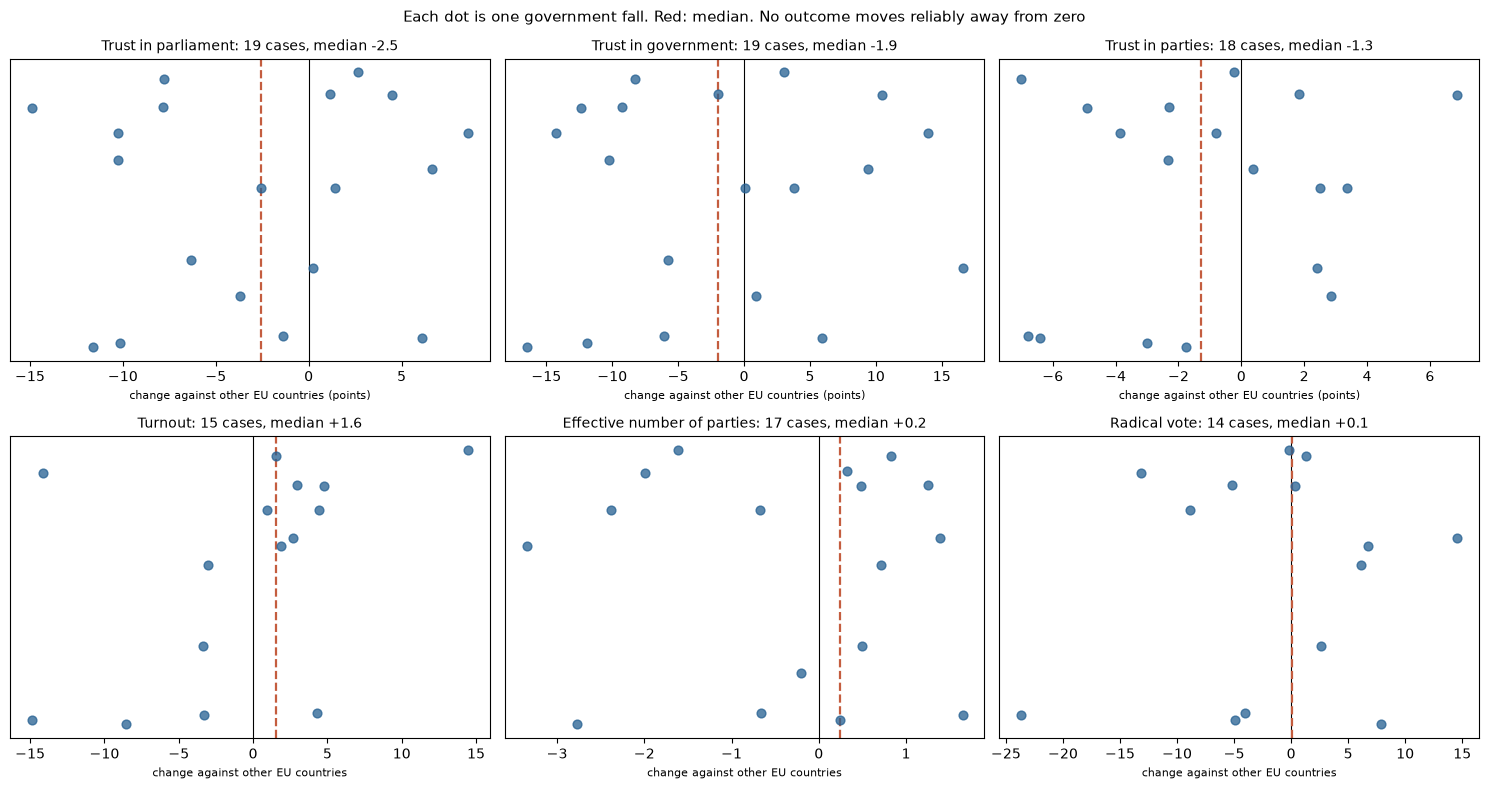

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (label, col, kind) in zip(axes.flat, OUTCOMES):
    v = sets[kind][col].dropna()
    ax.axvline(0, color='black', lw=0.8)
    ax.scatter(v, np.random.default_rng(0).uniform(-0.25, 0.25, len(v)), s=40, color=BLUE, alpha=0.75, zorder=3)
    ax.axvline(v.median(), color=RED, lw=1.6, ls='--', zorder=2)
    ax.set_yticks([])
    ax.set_xlabel('change against other EU countries' + (' (points)' if kind == 'trust' else ''), fontsize=8)
    ax.set_title(f"{label}: {len(v)} cases, median {v.median():+.1f}", fontsize=10)
fig.suptitle('Each dot is one government fall. Red: median. No outcome moves reliably away from zero', fontsize=11)
plt.tight_layout()
plt.show()

### Do the results survive a wider set of cases?

Trust is also measured on every case with a complete window, including the 12 where an election falls before the "after" survey, and the election outcomes on every case with a next election however far away.

In [22]:
usable = s1[s1.sample_group.isin(['clean', 'broad_only'])]
rows = []
for label, col, kind in OUTCOMES:
    wide = usable if kind == 'trust' else s1
    r = summarise(wide, col)
    rows.append({'Outcome': label, 'Cases used': 'all complete windows' if kind == 'trust' else 'any next election', **r})
wide_res = pd.DataFrame(rows).set_index('Outcome')
wide_res.style.format({'Mean': '{:+.2f}', 'Median': '{:+.2f}', 'Chance': '{:.3f}', 'Low': '{:+.2f}', 'High': '{:+.2f}'})

,Cases used,Cases,Countries,Mean,Median,Fell,Rose,Chance,Low,High
Outcome,,,,,,,,,,
Trust in parliament,all complete windows,31,18,+0.46,-1.00,16,15,0.804,-2.65,+4.61
Trust in government,all complete windows,31,18,+2.06,+0.93,14,17,0.314,-1.83,+6.85
Trust in parties,all complete windows,29,17,+0.14,-0.65,17,12,0.914,-1.66,+2.38
Turnout,any next election,31,16,-1.80,-1.40,17,14,0.219,-3.99,+1.60
Effective number of parties,any next election,33,18,+0.09,+0.24,13,20,0.721,-0.42,+0.50
Radical vote,any next election,28,16,+1.15,+0.78,12,16,0.510,-2.88,+3.57


### What the other outcomes say

In [23]:
from IPython.display import Markdown
strong = res[res['Clears the bar?'] == 'yes']
near = res[(res['Chance'] < 0.10) & (res['Clears the bar?'] == 'no')]
lines = [
    "- **No outcome moves reliably after a government falls.** " + (f"Only {', '.join(strong.index.str.lower())} clears the bar." if len(strong) else f"None of the {len(res)} clears the 0.008 bar, and every 95% range includes zero."),
    f"- **The nearest to a signal is {res['Chance'].idxmin().lower()}** (mean {res.loc[res['Chance'].idxmin(), 'Mean']:+.2f}, chance {res['Chance'].min():.2f}). With six outcomes tested, one at that level is expected by luck.",
    "- **Direction is mixed in every outcome.** For each, falls and rises are close to even, so a government falling does not push turnout, the party system or the radical vote one way.",
    "- **The election outcomes rest on 14 to 17 cases**, with big individual swings (some turnout changes of 14 points where a snap election followed the fall). That is a lot of room for a real effect to hide, not evidence of none.",
]
Markdown('\n'.join(l for l in lines if l))

- **No outcome moves reliably after a government falls.** None of the 6 clears the 0.008 bar, and every 95% range includes zero.
- **The nearest to a signal is trust in parliament** (mean -2.92, chance 0.09). With six outcomes tested, one at that level is expected by luck.
- **Direction is mixed in every outcome.** For each, falls and rises are close to even, so a government falling does not push turnout, the party system or the radical vote one way.
- **The election outcomes rest on 14 to 17 cases**, with big individual swings (some turnout changes of 14 points where a snap election followed the fall). That is a lot of room for a real effect to hide, not evidence of none.

**Limits of Part 3**

- **Few cases.** 14 to 19 per outcome. The tests can only rule out large effects; an average of 2 or 3 points would stay hidden.
- **Elections are far away.** Elections come on their own calendar. Using only elections within a year of the fall keeps the link plausible but loses cases.
- **Comparison countries are not matched in length.** Each comparison country's pair of elections straddles the same date but may be two or five years apart.
- **Radical vote is the weakest measure** (see the table at the top of Part 3).
- **Eurobarometer asks twice a year**, so short crises are blurred in the trust outcomes.